# Metadata and Potential Data Leakage

Metadata can contain information that indirectly identifies:

- hospitals
- scanners
- acquisition sites
- patient groups
- acquisition protocols

If such information is strongly correlated with the target,
the model may learn shortcuts rather than genuine pneumonia features.

For example:

If one scanner or hospital appears disproportionately
in positive cases, the model might learn scanner-specific
patterns instead of disease-related features.

Therefore metadata should be investigated before using it
as a model feature.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.analysis.metadata_analysis import (
    analyze_metadata,
    convert_age_to_years
)

In [2]:
image_dir = Path(
    "../data/raw/rsna-pneumonia-detection-challenge/stage_2_train_images"
)

print("Directory exists:", image_dir.exists())

Directory exists: True


In [3]:
total_images = len(
    list(image_dir.glob("*.dcm"))
)

print("Total DICOM images:", total_images)

Total DICOM images: 26684


In [4]:
SAMPLE_SIZE = 1000
RANDOM_STATE = 42

metadata_df = analyze_metadata(
    image_dir=image_dir,
    sample_size=SAMPLE_SIZE,
    random_state=RANDOM_STATE
)

print(
    "Images analyzed:",
    len(metadata_df)
)

Images analyzed: 1000


In [5]:
metadata_df.head()

,patient_id,age,sex,view_position,pixel_spacing_x,pixel_spacing_y,manufacturer,modality
0,6a4d75d0-51ae-4952-ad56-132474a2cf7b,43,M,PA,0.143,0.143,Unkown,CR
1,99ad8a84-90fd-460a-9818-263eab12ea0a,69,M,PA,0.143,0.143,Unkown,CR
2,e01ef6c8-20f4-48a3-8917-686da0e5b454,31,F,PA,0.168,0.168,Unkown,CR
3,38f85ed5-7251-48e9-8c52-234be2e3f9f9,29,F,AP,0.139,0.139,Unkown,CR
4,93c3cc21-67cb-44e7-bf5f-483c9168a52b,30,M,PA,0.139,0.139,Unkown,CR


In [6]:
metadata_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   patient_id       1000 non-null   str    
 1   age              1000 non-null   str    
 2   sex              1000 non-null   str    
 3   view_position    1000 non-null   str    
 4   pixel_spacing_x  1000 non-null   float64
 5   pixel_spacing_y  1000 non-null   float64
 6   manufacturer     1000 non-null   str    
 7   modality         1000 non-null   str    
dtypes: float64(2), str(6)
memory usage: 62.6 KB


In [7]:
metadata_df["age_years"] = (
    metadata_df["age"]
    .apply(convert_age_to_years)
)

In [8]:
metadata_df[
    ["age", "age_years"]
].head(10)

,age,age_years
0,43,43
1,69,69
2,31,31
3,29,29
4,30,30
5,35,35
6,27,27
7,61,61
8,44,44
9,43,43


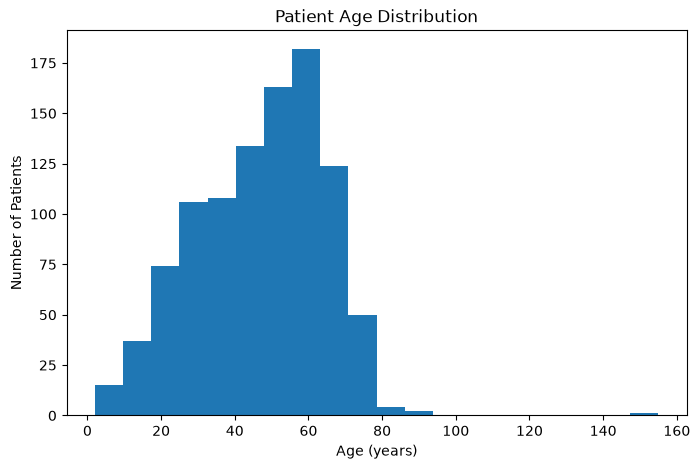

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(
    metadata_df["age_years"].dropna(),
    bins=20
)

plt.title("Patient Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Number of Patients")

plt.show()

In [10]:
metadata_df["age_years"].describe()

count    1000.000000
mean       46.933000
std        17.330865
min         2.000000
25%        34.000000
50%        49.000000
75%        60.000000
max       155.000000
Name: age_years, dtype: float64

In [11]:
metadata_df["sex"].value_counts()

sex
M    566
F    434
Name: count, dtype: int64

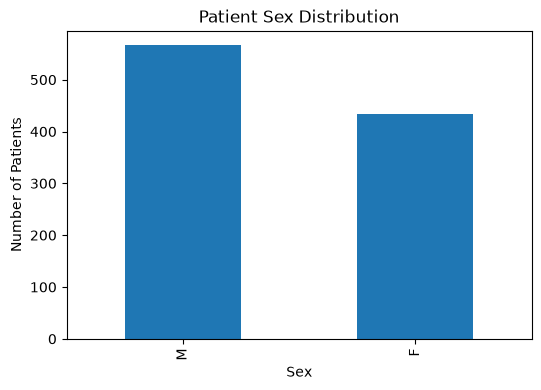

In [12]:
metadata_df["sex"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Patient Sex Distribution")
plt.xlabel("Sex")
plt.ylabel("Number of Patients")

plt.show()

In [13]:
metadata_df["view_position"].value_counts()

view_position
PA    560
AP    440
Name: count, dtype: int64

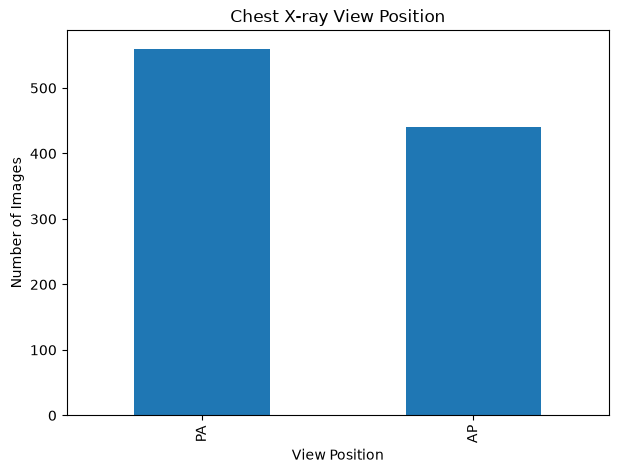

In [14]:
metadata_df["view_position"].value_counts().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Chest X-ray View Position")
plt.xlabel("View Position")
plt.ylabel("Number of Images")

plt.show()

In [15]:
metadata_df[
    [
        "pixel_spacing_x",
        "pixel_spacing_y"
    ]
].describe()

,pixel_spacing_x,pixel_spacing_y
count,1000.000000,1000.000000
mean,0.154799,0.154799
std,0.015892,0.015892
min,0.139000,0.139000
25%,0.143000,0.143000
50%,0.143000,0.143000
75%,0.168000,0.168000
max,0.194314,0.194314


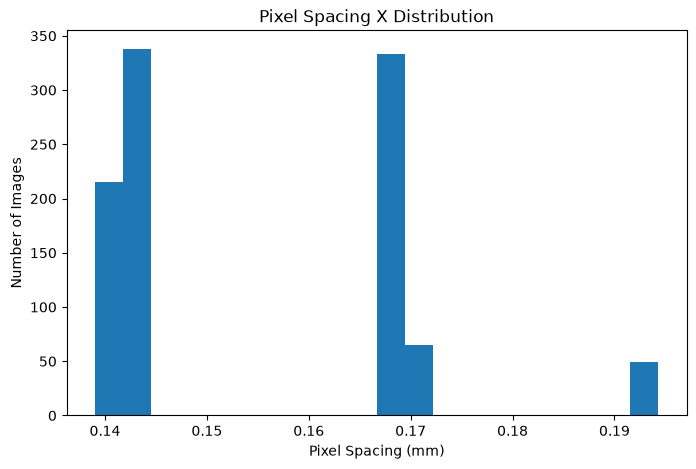

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(
    metadata_df["pixel_spacing_x"].dropna(),
    bins=20
)

plt.title("Pixel Spacing X Distribution")
plt.xlabel("Pixel Spacing (mm)")
plt.ylabel("Number of Images")

plt.show()

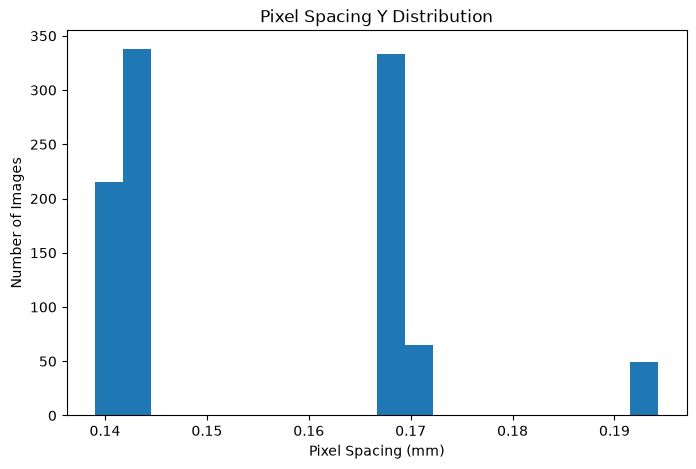

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(
    metadata_df["pixel_spacing_y"].dropna(),
    bins=20
)

plt.title("Pixel Spacing Y Distribution")
plt.xlabel("Pixel Spacing (mm)")
plt.ylabel("Number of Images")

plt.show()

In [18]:
metadata_df["manufacturer"].value_counts()

manufacturer
Unkown    1000
Name: count, dtype: int64

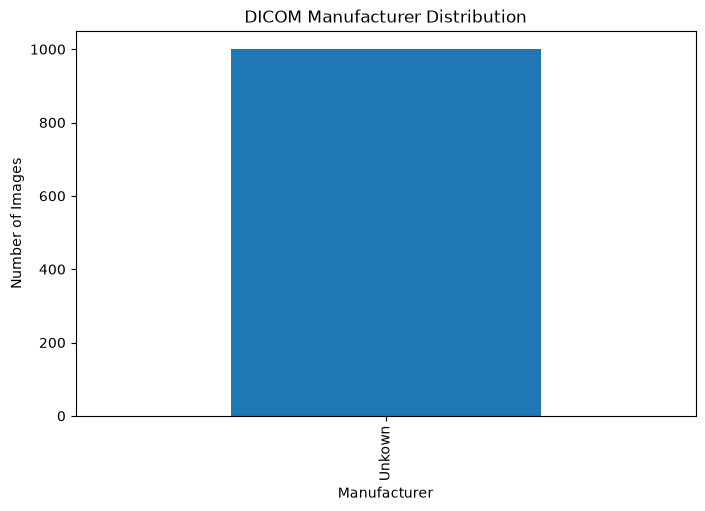

In [19]:
metadata_df["manufacturer"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("DICOM Manufacturer Distribution")
plt.xlabel("Manufacturer")
plt.ylabel("Number of Images")

plt.show()

In [20]:
metadata_df["modality"].value_counts()

modality
CR    1000
Name: count, dtype: int64

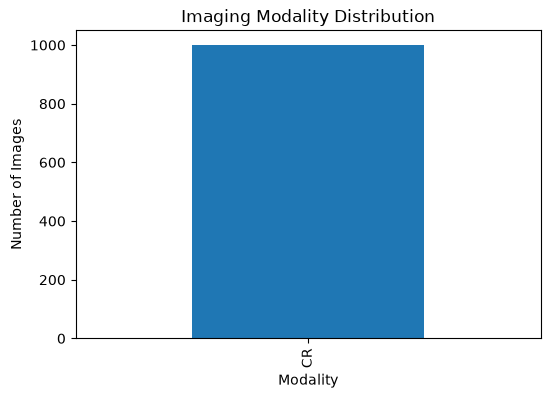

In [21]:
metadata_df["modality"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Imaging Modality Distribution")
plt.xlabel("Modality")
plt.ylabel("Number of Images")

plt.show()

In [22]:
missing_metadata = (
    metadata_df.isna().sum()
    .sort_values(
        ascending=False
    )
)

missing_metadata

patient_id         0
age                0
sex                0
view_position      0
pixel_spacing_x    0
pixel_spacing_y    0
manufacturer       0
modality           0
age_years          0
dtype: int64

In [23]:
missing_percentage = (
    metadata_df.isna().mean() * 100
).sort_values(
    ascending=False
)

missing_percentage

patient_id         0.0
age                0.0
sex                0.0
view_position      0.0
pixel_spacing_x    0.0
pixel_spacing_y    0.0
manufacturer       0.0
modality           0.0
age_years          0.0
dtype: float64

In [24]:
metadata_df.describe(
    include="all"
)

,patient_id,age,sex,view_position,pixel_spacing_x,pixel_spacing_y,manufacturer,modality,age_years
count,1000,1000,1000,1000,1000.000000,1000.000000,1000,1000,1000.000000
unique,1000,80,2,2,NaN,NaN,1,1,NaN
top,6a4d75d0-51ae-4952-ad56-132474a2cf7b,56,M,PA,NaN,NaN,Unkown,CR,NaN
freq,1,44,566,560,NaN,NaN,1000,1000,NaN
mean,NaN,NaN,NaN,NaN,0.154799,0.154799,NaN,NaN,46.933000
std,NaN,NaN,NaN,NaN,0.015892,0.015892,NaN,NaN,17.330865
min,NaN,NaN,NaN,NaN,0.139000,0.139000,NaN,NaN,2.000000
25%,NaN,NaN,NaN,NaN,0.143000,0.143000,NaN,NaN,34.000000
50%,NaN,NaN,NaN,NaN,0.143000,0.143000,NaN,NaN,49.000000
75%,NaN,NaN,NaN,NaN,0.168000,0.168000,NaN,NaN,60.000000
